# Tema 3 · Modelo colectivo de riesgo — Ejercicio práctico (Python)
**Luiz Luzuriaga** · Máster en Ciencias Actuariales y Financieras · Matemática Actuarial de la Estabilidad y Solvencia

Contenido: (A) ejemplo de Panjer de la teoría (λ=5, Gamma(2,300)), (B) Caso 1 Auto (Poisson–Gamma, λ=1.200),
(C) ajuste MLE de severidad (Gamma frente a Pareto), (D) Caso 2 Hogar (Binomial Negativa–Pareto),
(E) los cuatro segmentos del taller de Excel (aditividad del Poisson compuesto), (F) test de sobredispersión.
Se calcula siempre la distribución **exacta** (Panjer/FFT) y se compara con la aproximación **Normal** y **Normal Power**.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats, optimize

Z = stats.norm.ppf(0.995)

def discretizar(cdf, h, K):
    """Discretización central: f0=F(h/2), fj=F((j+½)h)−F((j−½)h); se renormaliza (como en la diapositiva)."""
    j = np.arange(K); f = np.empty(K)
    f[0] = cdf(h/2); f[1:] = cdf((j[1:] + .5)*h) - cdf((j[1:] - .5)*h)
    return f/f.sum()

def panjer_poisson(f, lam, K):
    """Recursión de Panjer, clase (a,b,0) con a=0, b=λ: g_k = (λ/k) Σ_{j=1}^{k} j f_j g_{k-j}."""
    g = np.zeros(K + 1); g[0] = np.exp(-lam*(1 - f[0])); jv = np.arange(len(f))*f
    for k in range(1, K + 1):
        m = min(k, len(f) - 1); j = np.arange(1, m + 1)
        g[k] = lam/k*np.sum(jv[j]*g[k - j])
    return g

def panjer_nb(f, r, beta, K):
    """Panjer para Binomial Negativa: a=β/(1+β), b=(r−1)β/(1+β); g0 = P_N(f0) = (1−β(f0−1))^−r."""
    a, b = beta/(1 + beta), (r - 1)*beta/(1 + beta)
    g = np.zeros(K + 1); g[0] = (1 - beta*(f[0] - 1))**(-r)
    for k in range(1, K + 1):
        m = min(k, len(f) - 1); j = np.arange(1, m + 1)
        g[k] = (1/(1 - a*f[0]))*np.sum((a + b*j/k)*f[j]*g[k - j])
    return g

def agg_fft(f, M, fgp):
    """g = IFFT( P_N(FFT(f)) ) con relleno de ceros hasta M puntos (evita el aliasing)."""
    fp = np.zeros(M); fp[:len(f)] = f
    return np.clip(np.fft.ifft(fgp(np.fft.fft(fp))).real, 0, None)

def cuantiles(g, h, ps):
    F = np.cumsum(g); return {p: h*int(np.searchsorted(F, p)) for p in ps}

def tvar(g, h, p):
    s = h*np.arange(len(g)); F = np.cumsum(g); v = np.searchsorted(F, p)
    # E[S | S >= VaR] con el reparto proporcional de la masa en el escalón del VaR
    exceso = F[v] - p
    return (np.sum(s[v+1:]*g[v+1:]) + s[v]*exceso)/(1 - p)

## (A) Ejemplo de Panjer de las diapositivas
$N\sim\text{Poisson}(5)$, $X\sim\Gamma(\alpha=2,\theta=300)$, malla $h=10$ €. Se aplica la recursión (clase $(a,b,0)$) y la FFT, y se comparan con los controles teóricos.

In [2]:
lam, alp, th, h = 5, 2, 300, 10
K = 1500
f = discretizar(lambda x: stats.gamma.cdf(x, alp, scale=th), h, 2048)   # m = 2048 puntos: soporte 0..20.470 €
g = panjer_poisson(f, lam, K)
Eth, Vth = lam*alp*th, lam*alp*th**2*(1 + alp)
s = h*np.arange(K + 1)
print(f"f0 = {f[0]:.9f}   g0 = {g[0]:.9f}   (diapositiva: 0,000137355 y 0,006742576)")
print(f"masa hasta {h*K} €: {g.sum():.9f}")
print(f"E[S]  Panjer = {np.sum(s*g):.4f}   teórico = {Eth}")
print(f"Var[S] Panjer = {np.sum(s**2*g) - np.sum(s*g)**2:.2f}   teórico = {Vth}")
q = cuantiles(g, h, (.5, .9, .95, .99, .995)); print("Cuantiles Panjer:", q)
gf = agg_fft(f, 2048, lambda z: np.exp(lam*(z - 1)))
print("FFT: máx |g_FFT − g_Panjer| =", np.max(np.abs(gf[:K+1] - g)), "   cuantiles:", cuantiles(gf, h, (.5, .9, .95, .99, .995)))

f0 = 0.000137355   g0 = 0.006742576   (diapositiva: 0,000137355 y 0,006742576)
masa hasta 15000 €: 0.999999184
E[S]  Panjer = 2999.9872   teórico = 3000
Var[S] Panjer = 2699917.47   teórico = 2700000
Cuantiles Panjer: {0.5: 2800, 0.9: 5210, 0.95: 6010, 0.99: 7640, 0.995: 8290}
FFT: máx |g_FFT − g_Panjer| = 2.815525590449397e-12    cuantiles: {0.5: 2800, 0.9: 5210, 0.95: 6010, 0.99: 7640, 0.995: 8290}


**Lectura.** La recursión y la FFT dan la misma distribución (discrepancia ~10⁻¹²) y reproducen la diapositiva: VaR 99,5 % = **8.290 €**. $g_0$ es algo mayor que $e^{-5}$
porque los siniestros inferiores a 5 € se redondean a cero.

## (B) Caso 1 — Auto: Poisson(1.200) y Gamma(2, 450)
$E(S)=1.080.000$, $\mathrm{Var}(S)=\lambda\alpha\theta^2(1+\alpha)=1{,}458\cdot10^9$. Con $\lambda=1.200$ la recursión directa desborda ($e^{-1200}=0$ en coma flotante); la FFT no tiene ese problema.

In [3]:
lam1, a1, t1, h1 = 1200, 2, 450, 10
M = 2**18
f1 = discretizar(lambda x: stats.gamma.cdf(x, a1, scale=t1), h1, 20000)
g1 = agg_fft(f1, M, lambda z: np.exp(lam1*(z - 1)))
E1, V1 = lam1*a1*t1, lam1*a1*t1**2*(1 + a1)
m3 = lam1*a1*(a1 + 1)*(a1 + 2)*t1**3                                  # μ3(S) = λ·E[X³] (Poisson compuesto)
sd1 = V1**.5; gam1 = m3/sd1**3
normal = E1 + Z*sd1; npw = E1 + sd1*(Z + gam1/6*(Z**2 - 1)); var_ex = cuantiles(g1, h1, (.995,))[.995]
tab = pd.DataFrame({"VaR 99,5 %": [normal, npw, var_ex]}, index=["Normal", "Normal Power", "Exacta (FFT)"])
tab["Capital = VaR − E(S)"] = tab["VaR 99,5 %"] - E1; tab["Capital / E(S) %"] = 100*tab["Capital = VaR − E(S)"]/E1
s1 = h1*np.arange(M)
print(f"E(S) = {np.sum(s1*g1):.1f}  (teórico {E1})   Var = {np.sum(s1**2*g1) - np.sum(s1*g1)**2:.0f}  (teórico {V1:.0f})   asimetría = {gam1:.4f}")
print(f"Suma g = {g1.sum():.12f}   P(S > soporte) ≈ {1 - g1.sum():.2e}")
tab.round(1)

E(S) = 1080000.0  (teórico 1080000)   Var = 1458010000  (teórico 1458000000)   asimetría = 0.0471
Suma g = 1.000000000000   P(S > soporte) ≈ -1.16e-13


,"VaR 99,5 %",Capital = VaR − E(S),Capital / E(S) %
Normal,1178354.9,98354.9,9.1
Normal Power,1180045.3,100045.3,9.3
Exacta (FFT),1180040.0,100040.0,9.3


**Lectura.** Con 1.200 siniestros esperados el TCL funciona y la Normal queda cerca (capital ≈ 98.000 €, 9 % de la prima de riesgo), pero persiste un déficit sistemático de unos 1.700 € respecto a la distribución exacta por la asimetría de la Gamma.

## (C) Ajuste MLE de la severidad: Gamma frente a Pareto (Lomax)
Muestra simulada de 500 siniestros $\Gamma(2,450)$ (semilla 123). Se ajustan por máxima verosimilitud una Gamma y una Pareto de dos parámetros (Lomax, $\theta$ escala, $\alpha$ forma) y se comparan por AIC.

In [4]:
rng = np.random.default_rng(123)
x = rng.gamma(2, 450, 500)
pg = stats.gamma.fit(x, floc=0); ll_g = np.sum(stats.gamma.logpdf(x, *pg)); aic_g = 2*2 - 2*ll_g
pp = stats.lomax.fit(x, floc=0); ll_p = np.sum(stats.lomax.logpdf(x, *pp)); aic_p = 2*2 - 2*ll_p
print(f"Gamma : forma = {pg[0]:.3f}  escala = {pg[2]:.1f}   logL = {ll_g:.2f}   AIC = {aic_g:.2f}")
print(f"Pareto: forma α = {pp[0]:.2f}  escala θ = {pp[2]:.0f}   logL = {ll_p:.2f}   AIC = {aic_p:.2f}")
if pp[0] > 1e6: print("   (la Pareto degenera hacia la exponencial: α→∞, sin evidencia de cola pesada)")
print("Mejor ajuste por AIC:", "Gamma" if aic_g < aic_p else "Pareto")
# Agregación con la Gamma estimada (λ = 1.200)
fg = discretizar(lambda z: stats.gamma.cdf(z, pg[0], scale=pg[2]), 10, 20000)
gg = agg_fft(fg, M, lambda z: np.exp(1200*(z - 1)))
Em = np.sum(s1*gg); Vm = np.sum(s1**2*gg) - Em**2
print(f"Con el ajuste MLE: E(S) = {Em:,.0f}   SD = {Vm**.5:,.0f}   VaR 99,5 % exacto = {cuantiles(gg, 10, (.995,))[.995]:,.0f}")

Gamma : forma = 2.065  escala = 439.4   logL = -3842.63   AIC = 7689.26
Pareto: forma α = 13221118129125.36  escala θ = 11997450910232808   logL = -3905.32   AIC = 7814.63
   (la Pareto degenera hacia la exponencial: α→∞, sin evidencia de cola pesada)
Mejor ajuste por AIC: Gamma
Con el ajuste MLE: E(S) = 1,088,935   SD = 38,296   VaR 99,5 % exacto = 1,189,250


**Lectura.** Los datos provienen de una Gamma y el AIC lo confirma (la Pareto de dos parámetros pierde por mucho). Con una muestra de 500 siniestros el error de estimación de los parámetros ya mueve el capital:
ese es un componente de **incertidumbre de parámetros** que el modelo de la diapositiva no incorpora.

## (D) Caso 2 — Hogar: Binomial Negativa(50, 3) y Pareto(4, 3.000)
$E(N)=r\beta=150$, $\mathrm{Var}(N)=r\beta(1+\beta)=600$. Pareto (Lomax): $E(X)=\theta/(\alpha-1)=1.000$, $\mathrm{Var}(X)=2\cdot10^6$, $E[X^3]$ existe porque $\alpha=4>3$ pero **no existe el cuarto momento**.
$\mathrm{Var}(S)=E(N)\mathrm{Var}(X)+\mathrm{Var}(N)E(X)^2$ y $\mu_3(S)=E(N)\mu_3(X)+3\mathrm{Var}(N)E(X)\mathrm{Var}(X)+\mu_3(N)E(X)^3$.

In [5]:
r, beta, al, thp = 50, 3, 4, 3000
EN, VN = r*beta, r*beta*(1 + beta); k3N = r*beta*(1 + beta)*(1 + 2*beta)
EX = thp/(al - 1); VX = al*thp**2/((al - 1)**2*(al - 2))
EX2 = 2*thp**2/((al - 1)*(al - 2)); EX3 = 6*thp**3/((al - 1)*(al - 2)*(al - 3)); m3X = EX3 - 3*EX*EX2 + 2*EX**3
ES2 = EN*EX; VS2 = EN*VX + VN*EX**2; m3S = EN*m3X + 3*VN*EX*VX + k3N*EX**3
sd2 = VS2**.5; gam2 = m3S/sd2**3
h2, M2 = 100, 2**13
f2 = discretizar(lambda z: stats.lomax.cdf(z, al, scale=thp), h2, M2)
g2 = agg_fft(f2, M2, lambda z: (1 - beta*(z - 1))**(-r))
gP = panjer_nb(f2, r, beta, 4000)
s2 = h2*np.arange(M2); F2 = np.cumsum(g2)
normal2 = ES2 + Z*sd2; np2 = ES2 + sd2*(Z + gam2/6*(Z**2 - 1)); var2 = cuantiles(g2, h2, (.995,))[.995]
rng = np.random.default_rng(123); n_sim = 100_000
Nsim = rng.negative_binomial(r, 1/(1 + beta), n_sim)                     # NB con media rβ
Ssim = np.array([stats.lomax.rvs(al, scale=thp, size=n, random_state=rng).sum() if n else 0 for n in Nsim[:20000]])
tab2 = pd.DataFrame({"VaR 99,5 %": [normal2, np2, var2, np.quantile(Ssim, .995)]}, index=["Normal", "Normal Power", "Exacta (FFT)", "Monte Carlo (20.000)"])
tab2["VaR / E(S) − 1 %"] = 100*(tab2["VaR 99,5 %"]/ES2 - 1)
print(f"E(S) = {ES2:.0f}  Var(S) = {VS2:.0f}  SD = {sd2:.0f}  asimetría = {gam2:.4f}   SD/E = {sd2/ES2:.3f}   (Caso 1: SD/E = {sd1/E1:.3f})")
print(f"Panjer(NB) = FFT: máx |g_P − g_FFT| = {np.max(np.abs(gP[:4001] - g2[:4001])):.2e}")
print(f"E(S) exacta = {np.sum(s2*g2):.0f}   TVaR 99,5 % = {tvar(g2, h2, .995):,.0f}")
tab2.round(1)

E(S) = 150000  Var(S) = 900000000  SD = 30000  asimetría = 0.4000   SD/E = 0.200   (Caso 1: SD/E = 0.035)
Panjer(NB) = FFT: máx |g_P − g_FFT| = 3.74e-11
E(S) exacta = 149917   TVaR 99,5 % = 252,671


,"VaR 99,5 %",VaR / E(S) − 1 %
Normal,227274.9,51.5
Normal Power,238544.7,59.0
Exacta (FFT),238300.0,58.9
Monte Carlo (20.000),238810.3,59.2


**Lectura.** Aunque la diapositiva afirma que ambas carteras tienen $SD/E$ «similar», no lo es: **3,5 % en Auto frente a 20 % en Hogar**.
La Normal da 227.275 (capital = 51 % de la media) y queda un 4,6 % corta del VaR exacto 238.300; la Normal Power (238.545) acierta casi de lleno porque con α=4 el tercer momento existe. La advertencia de la diapositiva se ve al bajar α (apartado G).

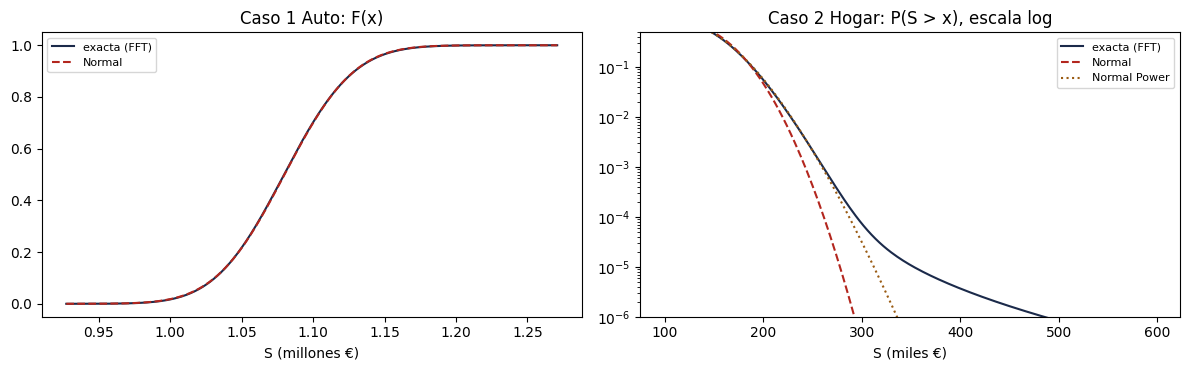

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
xs = np.arange(E1 - 4*sd1, E1 + 5*sd1, 100); i0 = (xs/h1).astype(int)
ax[0].plot(xs/1e6, np.cumsum(g1)[i0], color="#1b2a4a", label="exacta (FFT)")
ax[0].plot(xs/1e6, stats.norm.cdf((xs - E1)/sd1), color="#b3261e", ls="--", label="Normal"); ax[0].set_title("Caso 1 Auto: F(x)")
ax[0].set_xlabel("S (millones €)"); ax[0].legend(fontsize=8)
xs2 = np.arange(100000, 600000, 2000); sf = 1 - F2
ax[1].plot(xs2/1e3, sf[(xs2/h2).astype(int)], color="#1b2a4a", label="exacta (FFT)")
ax[1].plot(xs2/1e3, stats.norm.sf((xs2 - ES2)/sd2), color="#b3261e", ls="--", label="Normal")
yy = -3/gam2 + np.sqrt(9/gam2**2 + 1 + 6*((xs2 - ES2)/sd2)/gam2); ax[1].plot(xs2/1e3, stats.norm.sf(yy), color="#9a5b12", ls=":", label="Normal Power")
ax[1].set_yscale("log"); ax[1].set_ylim(1e-6, .5); ax[1].set_title("Caso 2 Hogar: P(S > x), escala log"); ax[1].set_xlabel("S (miles €)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## (G) ¿Qué pasa cuando la cola de la severidad engorda? Pareto con $E(X)=1.000$ fija y $lpha$ decreciente
Misma frecuencia que el Caso 2 (Binomial Negativa(50,3)); se fija la media $	heta=1000(lpha-1)$ para aislar el efecto de la cola. La Normal exige varianza finita ($lpha>2$) y la Normal Power, tercer momento ($lpha>3$).

In [7]:
filas = []
for al_ in (5, 4, 3.5, 3, 2.5, 2, 1.5):
    th_ = 1000*(al_ - 1); hG, MG = 250, 2**17
    fG = discretizar(lambda z: stats.lomax.cdf(z, al_, scale=th_), hG, MG)
    gG = agg_fft(fG, MG, lambda z: (1 - beta*(z - 1))**(-r)); EG = EN*1000
    vG = cuantiles(gG, hG, (.995,))[.995]
    VG = EN*al_*th_**2/((al_ - 1)**2*(al_ - 2)) + VN*1000**2 if al_ > 2 else np.nan
    nG = EG + Z*VG**.5 if al_ > 2 else np.nan
    if al_ > 3:
        EX2g = 2*th_**2/((al_ - 1)*(al_ - 2)); EX3g = 6*th_**3/((al_ - 1)*(al_ - 2)*(al_ - 3)); m3g = EX3g - 3*1000*EX2g + 2*1000**3
        VXg = EX2g - 1000**2; m3Sg = EN*m3g + 3*VN*1000*VXg + k3N*1000**3; npG = EG + VG**.5*(Z + m3Sg/VG**1.5/6*(Z**2 - 1))
    else: npG = np.nan
    filas.append([al_, th_, vG, vG/EG - 1, nG, npG, tvar(gG, hG, .995)])
cola = pd.DataFrame(filas, columns=["α", "θ", "VaR 99,5 % exacto", "VaR/E(S)−1", "Normal", "Normal Power", "TVaR 99,5 %"]).set_index("α")
cola["error Normal %"] = 100*(cola["Normal"]/cola["VaR 99,5 % exacto"] - 1)
cola.round(2)

,θ,"VaR 99,5 % exacto",VaR/E(S)−1,Normal,Normal Power,"TVaR 99,5 %",error Normal %
α,,,,,,,
5.0,4000.0,234000,0.56,225097.68,234710.15,246694.77,-3.80
4.0,3000.0,237750,0.58,227274.88,238544.67,252148.92,-4.41
3.5,2500.0,241750,0.61,229392.39,243924.49,259126.89,-5.11
3.0,2000.0,249750,0.66,233466.41,NaN,275924.40,-6.52
2.5,1500.0,269750,0.80,244642.01,NaN,325118.04,-9.31
2.0,1000.0,337500,1.25,NaN,NaN,505141.85,NaN
1.5,500.0,633750,3.22,NaN,NaN,1424418.23,NaN


**Lectura.** A igual media, el capital exacto crece de forma explosiva al engordar la cola: de +50 % de la media con α=5 a varias veces la media con α=1,5. La Normal da cifras que apenas cambian (y no existe con α≤2),
la Normal Power solo es aplicable con α>3. Con α cercano a 1 la media de S existe pero el capital está dominado por un único siniestro extremo: hay que usar Panjer/FFT, simulación o teoría de valores extremos (Tema 5).

## (E) Cuatro segmentos de Auto (taller de Excel): aditividad del Poisson compuesto
Segmento $j$: $\lambda_j$, $\Gamma(\alpha_j,\theta_j)$. La suma de Poisson compuestos independientes es Poisson compuesto con $\lambda=\sum\lambda_j$ y severidad **mezcla** ponderada por $\lambda_j$; basta sumar medias y varianzas.

In [8]:
seg = pd.DataFrame({"lam": [300, 250, 400, 250], "alpha": [2.0, 2.5, 1.8, 2.2], "theta": [400, 500, 350, 600]}, index=[1, 2, 3, 4])
seg["E[X]"] = seg.alpha*seg.theta; seg["E[X²]"] = seg.alpha*(seg.alpha + 1)*seg.theta**2; seg["E[X³]"] = seg.alpha*(seg.alpha + 1)*(seg.alpha + 2)*seg.theta**3
seg["E(S)"] = seg.lam*seg["E[X]"]; seg["Var(S)"] = seg.lam*seg["E[X²]"]; seg["μ3(S)"] = seg.lam*seg["E[X³]"]
T = seg[["E(S)", "Var(S)", "μ3(S)"]].sum(); sdT = T["Var(S)"]**.5; gT = T["μ3(S)"]/sdT**3
hh, MM = 50, 2**16                                      # soporte hasta 3,3 M€ (E(S) = 1,13 M€)
fseg = [discretizar(lambda z, a=a, t=t: stats.gamma.cdf(z, a, scale=t), hh, MM) for a, t in zip(seg.alpha, seg.theta)]
lamT = seg.lam.sum(); mezcla = sum(l*fk for l, fk in zip(seg.lam, fseg))/lamT
gT_ = agg_fft(mezcla, MM, lambda z: np.exp(lamT*(z - 1)))
# comprobación: producto de las 4 FFT de Poisson compuestos independientes
prod = np.ones(MM, complex)
for l, fk in zip(seg.lam, fseg):
    fp = np.zeros(MM); fp[:len(fk)] = fk; prod *= np.exp(l*(np.fft.fft(fp) - 1))
gprod = np.clip(np.fft.ifft(prod).real, 0, None)
print(seg.round(1).to_string()); print("\nTotales:", T.round(0).to_dict(), f"  SD = {sdT:,.0f}  asimetría = {gT:.4f}")
print(f"λ total = {lamT}   max |g_mezcla − g_producto| = {np.max(np.abs(gT_ - gprod)):.2e}")
v995 = cuantiles(gT_, hh, (.995,))[.995]; nrm = T['E(S)'] + Z*sdT; npw_ = T['E(S)'] + sdT*(Z + gT/6*(Z**2 - 1))
pd.DataFrame({"VaR 99,5 %": [nrm, npw_, v995]}, index=["Normal", "Normal Power", "Exacta (FFT)"]).round(0)

   lam  alpha  theta    E[X]      E[X²]         E[X³]      E(S)       Var(S)         μ3(S)
1  300    2.0    400   800.0   960000.0  1.536000e+09  240000.0  288000000.0  4.608000e+11
2  250    2.5    500  1250.0  2187500.0  4.921875e+09  312500.0  546875000.0  1.230469e+12
3  400    1.8    350   630.0   617400.0  8.211420e+08  252000.0  246960000.0  3.284568e+11
4  250    2.2    600  1320.0  2534400.0  6.386688e+09  330000.0  633600000.0  1.596672e+12

Totales: {'E(S)': 1134500.0, 'Var(S)': 1715435000.0, 'μ3(S)': 3616397550000.0}   SD = 41,418  asimetría = 0.0509
λ total = 1200   max |g_mezcla − g_producto| = 1.40e-17


,"VaR 99,5 %"
Normal,1241185.0
Normal Power,1243165.0
Exacta (FFT),1243150.0


**Lectura.** La mezcla con $\lambda=1.200$ y el producto de las cuatro transformadas coinciden (aditividad). Con tantos siniestros esperados la Normal es casi suficiente; la corrección de la Normal Power y la exacta difieren muy poco.

## (F) ¿Poisson o Binomial Negativa? Test de sobredispersión
Se simula una cartera de 20.000 pólizas con heterogeneidad no observada (tasa individual Gamma de media 0,15 y varianza 0,0225 · 2, es decir una mezcla Poisson–Gamma) y se contrasta frente a una Poisson.

In [9]:
rng = np.random.default_rng(7); npol = 20_000
tasa = rng.gamma(shape=0.5, scale=0.3, size=npol)                    # media 0,15; varianza 0,045
y = rng.poisson(tasa)
m, v = y.mean(), y.var(ddof=1); disp = v/m
chi2 = (npol - 1)*disp; pval = stats.chi2.sf(chi2, npol - 1)
ll_pois = stats.poisson.logpmf(y, m).sum()
def nll(p): rr, mu = np.exp(p); return -stats.nbinom.logpmf(y, rr, rr/(rr + mu)).sum()
op = optimize.minimize(nll, [0., np.log(m)]); rhat, muhat = np.exp(op.x); ll_nb = -op.fun
LR = 2*(ll_nb - ll_pois); p_LR = 0.5*stats.chi2.sf(LR, 1)              # contraste en la frontera: mezcla ½χ²₀+½χ²₁
print(f"media = {m:.4f}  varianza = {v:.4f}  índice de dispersión = {disp:.3f}   χ² = {chi2:.0f}  p = {pval:.2e}")
print(f"NB (MLE): r = {rhat:.3f}  media = {muhat:.4f}  Var = {muhat + muhat**2/rhat:.4f}")
print(f"logL Poisson = {ll_pois:.1f}   logL NB = {ll_nb:.1f}   LR = {LR:.1f}   p ≈ {p_LR:.1e}   AIC: Poisson {2 - 2*ll_pois:.1f} vs NB {4 - 2*ll_nb:.1f}")
obs = np.bincount(y)[:6]; esp_p = npol*stats.poisson.pmf(np.arange(6), m); esp_n = npol*stats.nbinom.pmf(np.arange(6), rhat, rhat/(rhat + muhat))
pd.DataFrame({"observado": obs, "Poisson": esp_p.round(0), "Bin. Negativa": esp_n.round(0)}, index=range(6))

media = 0.1514  varianza = 0.2024  índice de dispersión = 1.337   χ² = 26738  p = 6.86e-205
NB (MLE): r = 0.453  media = 0.1514  Var = 0.2019
logL Poisson = -9203.6   logL NB = -8910.1   LR = 587.1   p ≈ 5.3e-130   AIC: Poisson 18409.3 vs NB 17824.2


,observado,Poisson,Bin. Negativa
0,17551,17191.0,17552.0
1,1997,2602.0,1991.0
2,352,197.0,362.0
3,82,10.0,74.0
4,11,0.0,16.0
5,6,0.0,4.0


**Lectura.** El índice de dispersión $\mathrm{Var}/\mathrm{media}\approx1{,}3$ (frente a 1 si fuera Poisson), el contraste χ² y la razón de verosimilitudes rechazan la Poisson con p ≈ 0; la Binomial Negativa reproduce los recuentos observados.
Ignorar esa sobredispersión subestima $\mathrm{Var}(S)$: el término $\mathrm{Var}(N)E(X)^2$ crece justo en proporción.